### 1. Imports and configuration

In [1]:
import sys
import hashlib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torchtuples as tt
import matplotlib.pyplot as plt
import seaborn as sns

from lifelines import KaplanMeierFitter
from pycox.models import LogisticHazard

# ============================================================
# Project setup
# ============================================================

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name in {"notebooks", "scripts"}:
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))
sys.path.insert(0, str(PROJECT_ROOT / "src"))

FIGURE_DIR = PROJECT_ROOT / "figures"
RESULT_DIR = PROJECT_ROOT / "results"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

from explanation_plot_utils import (
    DEFAULT_COLORS, load_explanations, msk_importance_summary,
    plot_global, plot_temporal, style_axis,
)

from examples.data.MSK import load_MSK
from examples.learner.coxsig import CoxSignature
from examples.learner.dynamic_deephit_ext import construct_df, Dynamic_DeepHit_ext
from examples.learner.utils import score
from examples.learner.DySurv.model_utils import DySurv, Loss
from examples.learner.dysurv_ext import (
    DySurvWrapper,
    make_dysurv_input,
    add_duration_channel,
)

warnings.filterwarnings("ignore")
sns.set(style="whitegrid", font="STIXGeneral", context="talk", palette="colorblind")


# ============================================================
# Experiment configuration
# ============================================================

seed = 0
np.random.seed(seed)
torch.manual_seed(seed)

train_test_share = 0.8
val_ratio = 0.1

quantile_pred_times = np.array([0.25, 0.50])
n_eval_times = 3
eval_quantile_step = 0.15

num_durations = 10
latent_dim = 20
batch_size = 32
epochs = 200
patience = 20
learning_rate = 1e-3

FORCE_RETRAIN_DDH = False
FORCE_RETRAIN_DYSURV = False

MODEL_LABELS = {"CoxSig": "CoxSig explanation", "DDH": "DDH explanation", "DySurv": "DySurv explanation"}
COLORS = DEFAULT_COLORS

/Users/vantnguy/Working/survinsights/.venv_survinsights_longi/lib/python3.12/site-packages/keras/src/export/tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


### 2. MSK-Chord dataset and train/test split

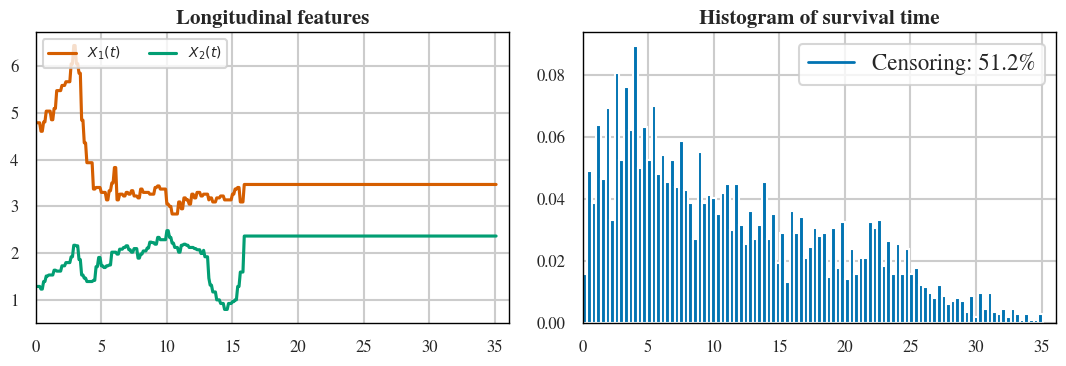

Prediction times: [3.29999995 6.4000001 ]
Evaluation horizons: [ 2.5999999   5.9000001  13.95999937]


In [2]:
# ============================================================
# Load MSK data
# ============================================================

paths, surv_labels, longi_feat_list, static_feature, static_feature_list, ddh_info_sup = load_MSK.load()

paths = torch.as_tensor(paths, dtype=torch.float32)
surv_labels = np.asarray(surv_labels, dtype=np.float32)

static_feature = (
    None if static_feature is None
    else np.asarray(static_feature, dtype=np.float32)
)

n_samples = len(paths)
sampling_times = np.asarray(paths[0, :, 0])
dt = sampling_times[1] - sampling_times[0]

# ---------- Train / validation / test split ----------
indices = np.random.permutation(n_samples)

n_train = int(train_test_share * n_samples)
train_index = indices[:n_train]
test_index = indices[n_train:]

n_fit = int((1 - val_ratio) * len(train_index))
fit_index = train_index[:n_fit]
val_index = train_index[n_fit:]

paths_train = paths[train_index]
paths_test = paths[test_index]

surv_labels_train = surv_labels[train_index]
surv_labels_test = surv_labels[test_index]

static_feature_train = (
    None if static_feature is None
    else static_feature[train_index]
)

static_feature_test = (
    None if static_feature is None
    else static_feature[test_index]
)


# ============================================================
# Prediction times and evaluation horizons
# ============================================================

tte = surv_labels[surv_labels[:, 1] == 1, 0]

pred_times = np.quantile(tte, quantile_pred_times)

eval_times = np.array([
    np.max(
        np.quantile(
            tte,
            np.minimum(
                quantile_pred_times + (k + 1) * eval_quantile_step,
                1.0,
            ),
        ) - pred_times
    )
    for k in range(n_eval_times)
])

print("Prediction times:", pred_times)
print("Evaluation horizons:", eval_times)

n_longi_feats = paths.shape[-1] - 1
FEATURE_LABELS = ["CEA", "CA 15-3", "Stage", "Age", "Smoking", "HR", "HER2"]
if len(FEATURE_LABELS) != n_longi_feats + (0 if static_feature is None else static_feature.shape[1]):
    raise ValueError("Feature labels do not match MSK data dimensions")

### 3. Train and evaluate CoxSig

In [3]:
coxsig = CoxSignature(
    sig_level=2,
    alphas=5e-2,
    max_iter=100,
)

coxsig.train(
    paths_train,
    surv_labels_train,
    static_feature_train,
    plot_loss=False,
)

coxsig_cindex = coxsig.score(
    paths_test,
    surv_labels_test,
    pred_times,
    eval_times,
    "c_index",
    static_feat=static_feature_test,
)

coxsig_bs = coxsig.score(
    paths_test,
    surv_labels_test,
    pred_times,
    eval_times,
    "bs",
    static_feat=static_feature_test,
)

### 4. Train and evaluate Dynamic DeepHit

In [4]:
cont_feat, bin_feat, time_scale, bin_df = ddh_info_sup

df = construct_df(
    torch.as_tensor(paths).clone(),
    surv_labels,
    cont_feat,
    bin_feat,
    time_scale,
    bin_df,
)

dynamic_deephit = Dynamic_DeepHit_ext()

(data, time_, label), (mask1, mask2, mask3), data_mi = (
    dynamic_deephit.preprocess(df, cont_feat, bin_feat)
)

dynamic_deephit.sampling_times = sampling_times
dynamic_deephit.ddh_info_sup = ddh_info_sup

tr_data_full = (
    data[train_index],
    data_mi[train_index],
    label[train_index],
    time_[train_index],
    mask1[train_index],
    mask2[train_index],
    mask3[train_index],
)

# ---------- Train or load checkpoint ----------
ddh_ckpt_dir = RESULT_DIR / "dynamic_deephit_ckpt" / "MSK"
ddh_ckpt_dir.mkdir(parents=True, exist_ok=True)

ddh_checkpoint = ddh_ckpt_dir / "model.weights.h5"

dynamic_deephit.train(
    tr_data_full,
    is_trained=ddh_checkpoint.is_file() and not FORCE_RETRAIN_DDH,
    ckpt_dir=str(ddh_ckpt_dir),
    plot_loss=False,
)

# ---------- Predict ----------
pred_time_scale = (pred_times * time_scale).astype(int)
eval_time_scale = (eval_times * time_scale).astype(int)

ddh_surv_preds = dynamic_deephit.predict(
    data[test_index],
    data_mi[test_index],
    pred_time_scale,
    eval_time_scale,
)

ddh_cindex = np.full((len(pred_times), len(eval_times)), np.nan)
ddh_bs = np.full_like(ddh_cindex, np.nan)

for j, pred_time in enumerate(pred_times):
    idx_sel = surv_labels_test[:, 0] >= pred_time

    if not np.any(idx_sel):
        continue

    surv_labels_ = np.column_stack([
        surv_labels_test[idx_sel, 0] - pred_time,
        surv_labels_test[idx_sel, 1],
    ])

    surv_preds_ = ddh_surv_preds[:, j][idx_sel]

    ddh_cindex[j] = score(
        "c_index",
        surv_labels_,
        surv_labels_,
        surv_preds_,
        eval_times,
    )

    ddh_bs[j] = score(
        "bs",
        surv_labels_,
        surv_labels_,
        surv_preds_,
        eval_times,
    )

### 5. Train and evaluate DySurv

In [5]:
# ---------- Prepare training data ----------
x_fit = make_dysurv_input(
    paths[fit_index],
    None if static_feature is None else static_feature[fit_index],
)

x_val = make_dysurv_input(
    paths[val_index],
    None if static_feature is None else static_feature[val_index],
)

labtrans = LogisticHazard.label_transform(num_durations)

y_fit = labtrans.fit_transform(
    surv_labels[fit_index, 0],
    surv_labels[fit_index, 1].astype(int),
)

y_val = labtrans.transform(
    surv_labels[val_index, 0],
    surv_labels[val_index, 1].astype(int),
)

train_input = add_duration_channel(x_fit, y_fit)
val_input = add_duration_channel(x_val, y_val)

train = tt.tuplefy(train_input, (y_fit, train_input))
val = tt.tuplefy(val_input, (y_val, val_input))

# ---------- Initialize model ----------
net = DySurv(
    in_features=x_fit.shape[2],
    encoded_features=latent_dim,
    out_features=labtrans.out_features,
    seq_len=x_fit.shape[1],
)

dysurv_model = LogisticHazard(
    net,
    tt.optim.Adam(learning_rate),
    duration_index=labtrans.cuts,
    loss=Loss([1.0, 0.1, 0.01]),
)

# ---------- Train or load checkpoint ----------
dysurv_ckpt_dir = RESULT_DIR / "dysurv_ckpt" / "MSK"
dysurv_ckpt_dir.mkdir(parents=True, exist_ok=True)

dysurv_checkpoint = dysurv_ckpt_dir / "model.pt"

def array_digest(*arrays):
    digest = hashlib.sha256()
    for array in arrays:
        if array is None:
            digest.update(b"none")
            continue
        array = np.ascontiguousarray(np.asarray(array))
        digest.update(str((array.shape, array.dtype)).encode())
        digest.update(array.tobytes())
    return digest.hexdigest()

checkpoint_config = {
    "num_durations": num_durations,
    "latent_dim": latent_dim,
    "input_shape": tuple(x_fit.shape[1:]),
    "data_digest": array_digest(np.asarray(paths), surv_labels, static_feature,
                                train_index, test_index, fit_index, val_index),
}

if dysurv_checkpoint.is_file() and not FORCE_RETRAIN_DYSURV:
    checkpoint = torch.load(
        dysurv_checkpoint,
        map_location="cpu",
        weights_only=False,
    )

    if checkpoint.get("config") != checkpoint_config:
        raise ValueError("DySurv checkpoint/data mismatch; set FORCE_RETRAIN_DYSURV=True")

    saved_cuts = np.asarray(checkpoint["duration_index"])

    if not np.allclose(saved_cuts, labtrans.cuts):
        raise ValueError("DySurv checkpoint duration cuts mismatch.")

    dysurv_model.net.load_state_dict(checkpoint["model_state_dict"])
    print("Loaded DySurv checkpoint.")

else:
    dysurv_model.fit(
        *train,
        batch_size=batch_size,
        epochs=epochs,
        val_data=val,
        callbacks=[tt.cb.EarlyStopping(patience=patience)],
        verbose=False,
    )

    torch.save(
        {
            "model_state_dict": dysurv_model.net.state_dict(),
            "duration_index": np.asarray(labtrans.cuts),
            "config": checkpoint_config,
        },
        dysurv_checkpoint,
    )

    print("Saved DySurv checkpoint.")

dysurv_model.net.eval()
dysurv = DySurvWrapper(dysurv_model)

# ---------- Evaluate ----------
censor_km = KaplanMeierFitter()

censor_km.fit(
    durations=surv_labels_train[:, 0],
    event_observed=1 - surv_labels_train[:, 1].astype(int),
)

dysurv_cindex = np.full((len(pred_times), len(eval_times)), np.nan)
dysurv_bs = np.full_like(dysurv_cindex, np.nan)

for j, pred_time in enumerate(pred_times):
    dysurv_cindex[j] = dysurv.score(
        paths_test,
        surv_labels_test,
        pred_time,
        eval_times,
        metric="c_index",
        static_feat=static_feature_test,
    )

    dysurv_bs[j] = dysurv.score(
        paths_test,
        surv_labels_test,
        pred_time,
        eval_times,
        metric="bs",
        static_feat=static_feature_test,
        censor_km=censor_km,
    )

Loaded DySurv checkpoint.


### 6. Performance comparison

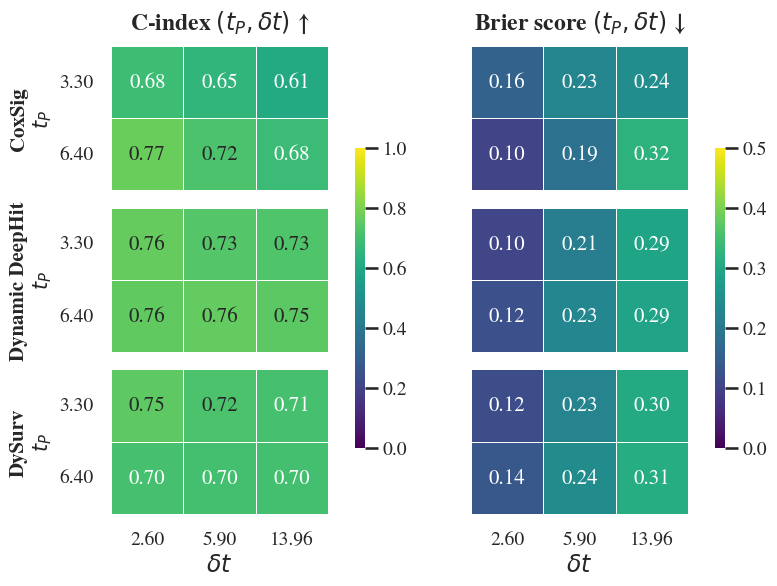


========== MSK model comparison ==========
          Model  Mean C-index  Mean Brier score
         CoxSig        0.6860            0.2057
Dynamic DeepHit        0.7474            0.2080
         DySurv        0.7133            0.2219

Saved MSK-Seq evaluation results.


In [6]:
# ============================================================
# Compact performance heatmaps — MSK
# ============================================================

models = ["CoxSig", "Dynamic DeepHit", "DySurv"]
cindex_results = [coxsig_cindex, ddh_cindex, dysurv_cindex]
bs_results = [coxsig_bs, ddh_bs, dysurv_bs]

expected_shape = (len(pred_times), len(eval_times))
n_longi_feats = paths.shape[-1] - 1

for model, cindex, bs in zip(models, cindex_results, bs_results):
    if np.shape(cindex) != expected_shape or np.shape(bs) != expected_shape:
        raise ValueError(f"Unexpected performance shape for {model}")

fig, axs = plt.subplots(3, 2, figsize=(9, 6))

plt.subplots_adjust(
    left=0.16, right=0.88, bottom=0.12, top=0.90,
    hspace=0.12, wspace=0.25,
)

# ---------- Shared colorbars ----------
cbar_ax_1 = fig.add_axes([0.47, 0.23, 0.012, 0.50])
cbar_ax_2 = fig.add_axes([0.87, 0.23, 0.012, 0.50])

# ---------- Heatmaps ----------
for i, model in enumerate(models):
    for j, (values, vmin, vmax, cbar_ax) in enumerate([
        (cindex_results[i], 0, 1, cbar_ax_1),
        (bs_results[i], 0, 0.5, cbar_ax_2),
    ]):
        ax = axs[i, j]

        sns.heatmap(
            values,
            annot=True,
            fmt=".2f",
            annot_kws={"size": 15},
            cmap="viridis",
            vmin=vmin,
            vmax=vmax,
            square=True,
            linewidths=0.5,
            linecolor="white",
            ax=ax,
            cbar=(i == 2),
            cbar_ax=cbar_ax if i == 2 else None,
        )

        # ---------- Shared x-axis labels ----------
        if i == 2:
            ax.set_xticklabels(
                [f"{x:.2f}" for x in eval_times],
                rotation=0,
                fontsize=14,
            )
            ax.set_xlabel(
                r"$\delta t$",
                fontsize=17,
                fontweight="semibold",
            )
        else:
            ax.set_xticks([])

        # ---------- Shared y-axis labels ----------
        if j == 0:
            ax.set_yticklabels(
                [f"{x:.2f}" for x in pred_times],
                rotation=0,
                fontsize=14,
            )
            ax.set_ylabel(
                f"{model}\n$t_P$",
                fontsize=15,
                fontweight="semibold",
            )
        else:
            ax.set_yticks([])
            ax.set_ylabel("")

        if i == 0:
            ax.set_title(
                r"C-index $(t_P,\delta t)$ ↑" if j == 0
                else r"Brier score $(t_P,\delta t)$ ↓",
                fontsize=17,
                fontweight="semibold",
                pad=12,
            )

# ---------- Colorbar formatting ----------
for cbar_ax in [cbar_ax_1, cbar_ax_2]:
    cbar_ax.tick_params(labelsize=14)

# ---------- Save figure ----------
fig.savefig(
    FIGURE_DIR / "MSK_perf_comparison.pdf",
    bbox_inches="tight",
    dpi=300,
)

plt.show()


# ============================================================
# Save evaluation results — MSK
# ============================================================

results = {
    model: (cindex, bs)
    for model, cindex, bs in zip(models, cindex_results, bs_results)
}

for model_name, (cindex, bs) in results.items():
    name = model_name.replace(" ", "_")

    np.save(RESULT_DIR / f"MSK_{name}_cindex.npy", cindex)
    np.save(RESULT_DIR / f"MSK_{name}_bs.npy", bs)

np.savez(
    RESULT_DIR / "MSK_experiment_config.npz",
    train_index=train_index,
    test_index=test_index,
    fit_index=fit_index,
    val_index=val_index,
    pred_times=pred_times,
    eval_times=eval_times,
    seed=seed,
)

# ---------- Summary table ----------
summary = pd.DataFrame([
    {
        "Model": model,
        "Mean C-index": np.nanmean(cindex),
        "Mean Brier score": np.nanmean(bs),
    }
    for model, (cindex, bs) in results.items()
])

summary.to_csv(
    RESULT_DIR / "MSK_model_comparison.csv",
    index=False,
)

print("\n========== MSK model comparison ==========")
print(summary.round(4).to_string(index=False))
print("\nSaved MSK-Seq evaluation results.")

### 7. Explanation utilities

In [7]:
# MSK uses the original finite-value filter, global mean across individuals,
# and temporal ±1 SD (not 95% CI), to preserve the original results.
explanations = {}

def get_summaries(explanation_kind="mean"):
    if explanation_kind not in explanations:
        explanations[explanation_kind] = {
            model: [msk_importance_summary(results, idx) for idx in range(len(pred_times))]
            for model, results in load_explanations(
                RESULT_DIR, "MSK", explanation_kind, tuple(MODEL_LABELS)
            ).items()
        }
    return explanations[explanation_kind]

def prediction_end_time(prediction_idx):
    # Original MSK notebook rounds to the nearest sampling grid point.
    pred_time_idx = int(np.floor(pred_times[prediction_idx] / float(dt) + 0.5))
    return float(pred_time_idx * dt)

def save_figure(fig, filename):
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / filename, bbox_inches="tight", dpi=300)
    plt.show()

### 8. Global and temporal importance across prediction times

In [8]:
# ============================================================
# Shared comparison: mean and median explanations
# ============================================================

def compare_models(explanation_kind="mean", view="global", y_limits=None):
    summaries = get_summaries(explanation_kind)
    fig, axes = plt.subplots(len(pred_times), len(MODEL_LABELS),
                             figsize=(18, 4.5 * len(pred_times)), squeeze=False)

    for prediction_idx, prediction_time in enumerate(pred_times):
        for col, model in enumerate(MODEL_LABELS):
            summary = summaries[model][prediction_idx]
            ax = axes[prediction_idx, col]

            if view == "global":
                plot_global(ax, summary.global_mean, summary.global_ci,
                            labels=FEATURE_LABELS, colors=COLORS,
                            separator=n_longi_feats - 0.5)
            elif view == "temporal":
                plot_temporal(ax, summary.temporal_mean, summary.temporal_ci,
                              sampling_times, n_longi_feats, FEATURE_LABELS, COLORS)
                ax.set_xlim(0, prediction_end_time(prediction_idx))
                if prediction_idx == len(pred_times) - 1:
                    ax.set_xlabel(r"Time $(t)$", fontsize=18)
            else:
                raise ValueError("view must be 'global' or 'temporal'")

            limit = None if y_limits is None else (
                y_limits.get(model) if isinstance(y_limits, dict) else y_limits[prediction_idx]
            )
            style_axis(ax, MODEL_LABELS[model] if prediction_idx == 0 else None, limit)

            if col == 0:
                # ylabel = "Feature importance" if view == "global" else "Interval-wise importance"
                # ax.set_ylabel(rf"$t_P = {prediction_time:.2f}$" + "\n" + ylabel,
                #               fontsize=18, fontweight="semibold")
                ax.set_ylabel(("Feature importance" if view == "global" else "Interval-wise importance")
                              + f"\n($t_P={prediction_time:.2f}$)", fontweight="semibold")

    if view == "temporal":
        axes[0, 0].legend(ncols=2, fontsize=15)
        # handles, labels = axes[0, 0].get_legend_handles_labels()
        # fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 1.02),
        #            ncol=len(labels), fontsize=13, frameon=False)

    suffix = "feat" if view == "global" else "longi"
    save_figure(fig, f"shap_MSK_{explanation_kind}_score_per_{suffix}.pdf")

### 9. Mean explanation

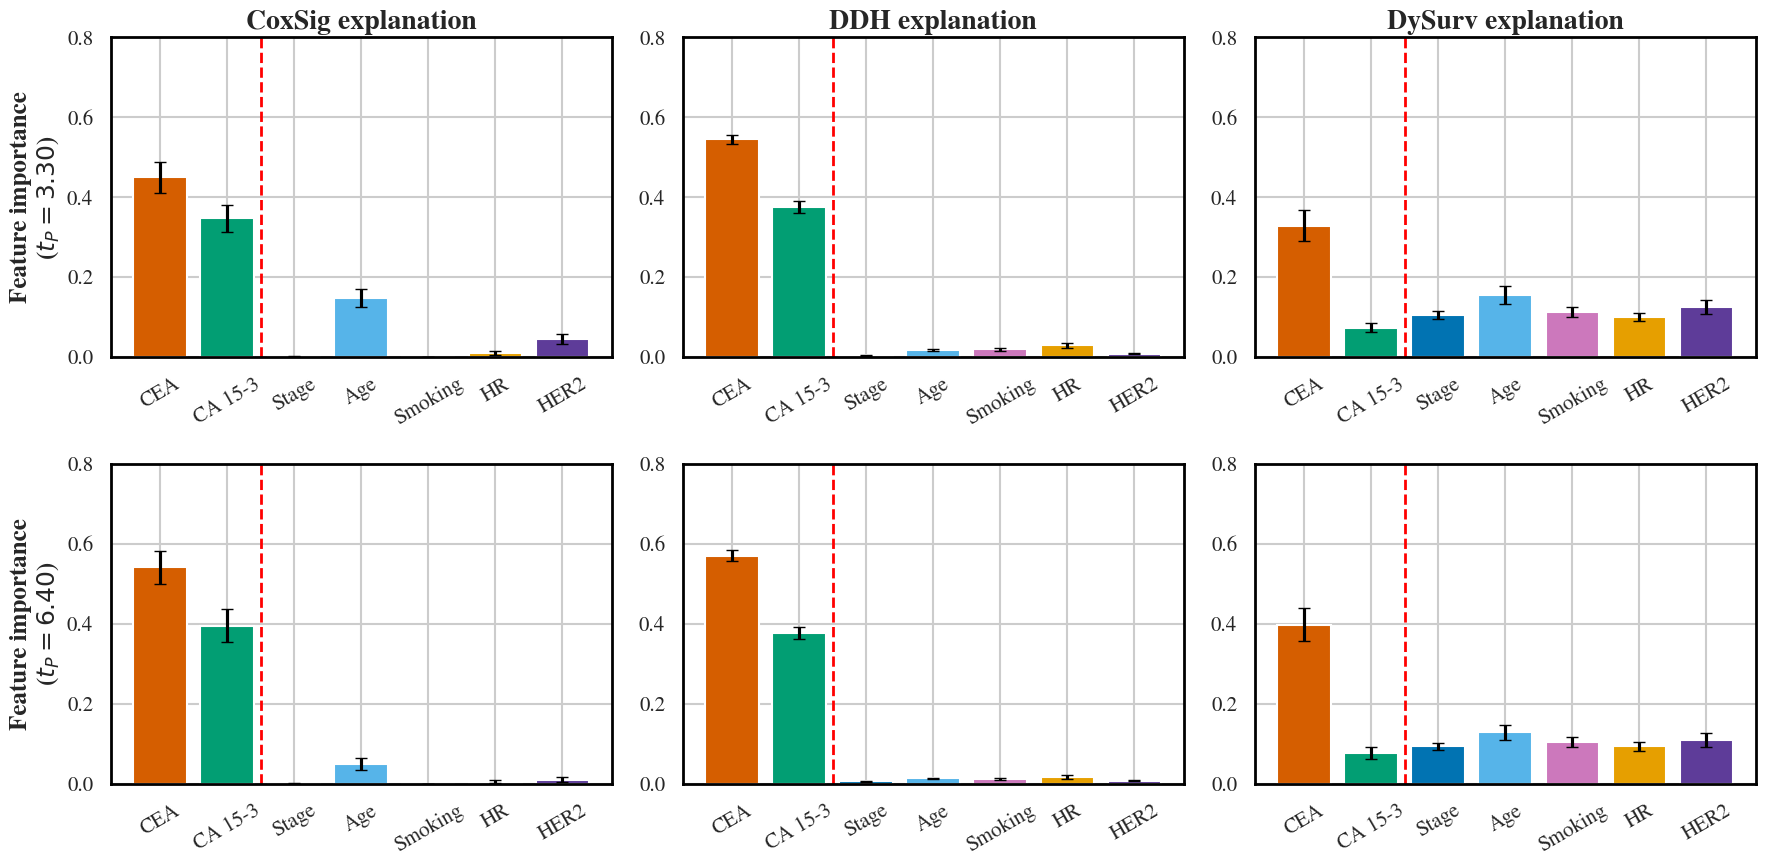

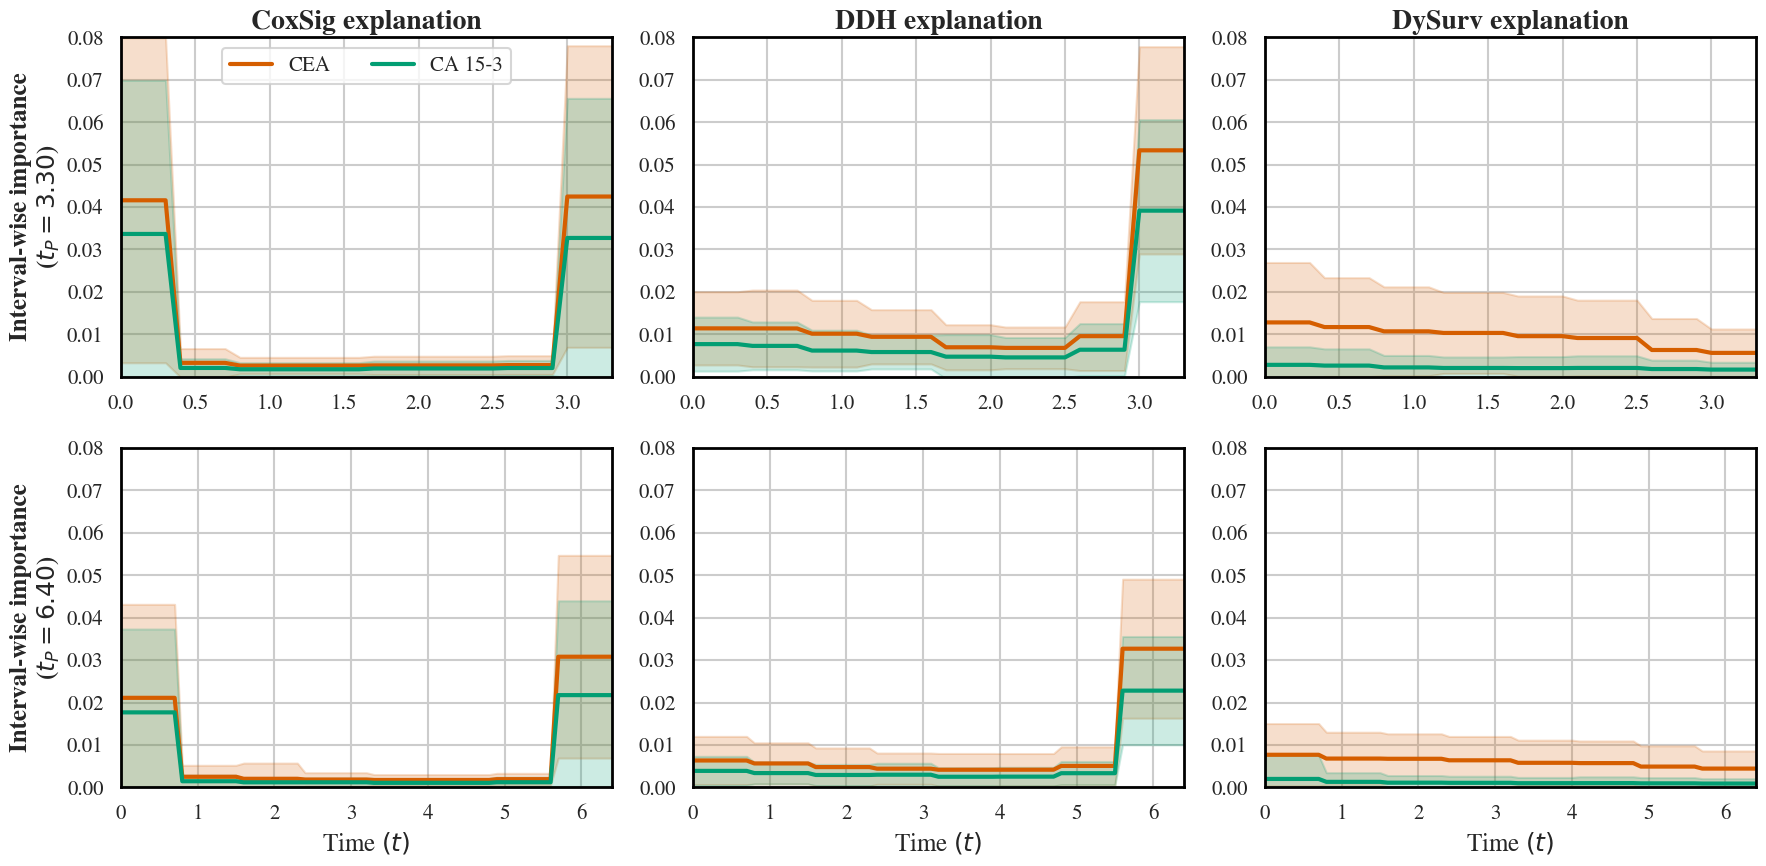

In [9]:
compare_models("mean", "global", y_limits=[(0, 0.8)] * len(pred_times))
compare_models("mean", "temporal", y_limits=[(0, 0.08)] * len(pred_times))

### 10. Median explanation

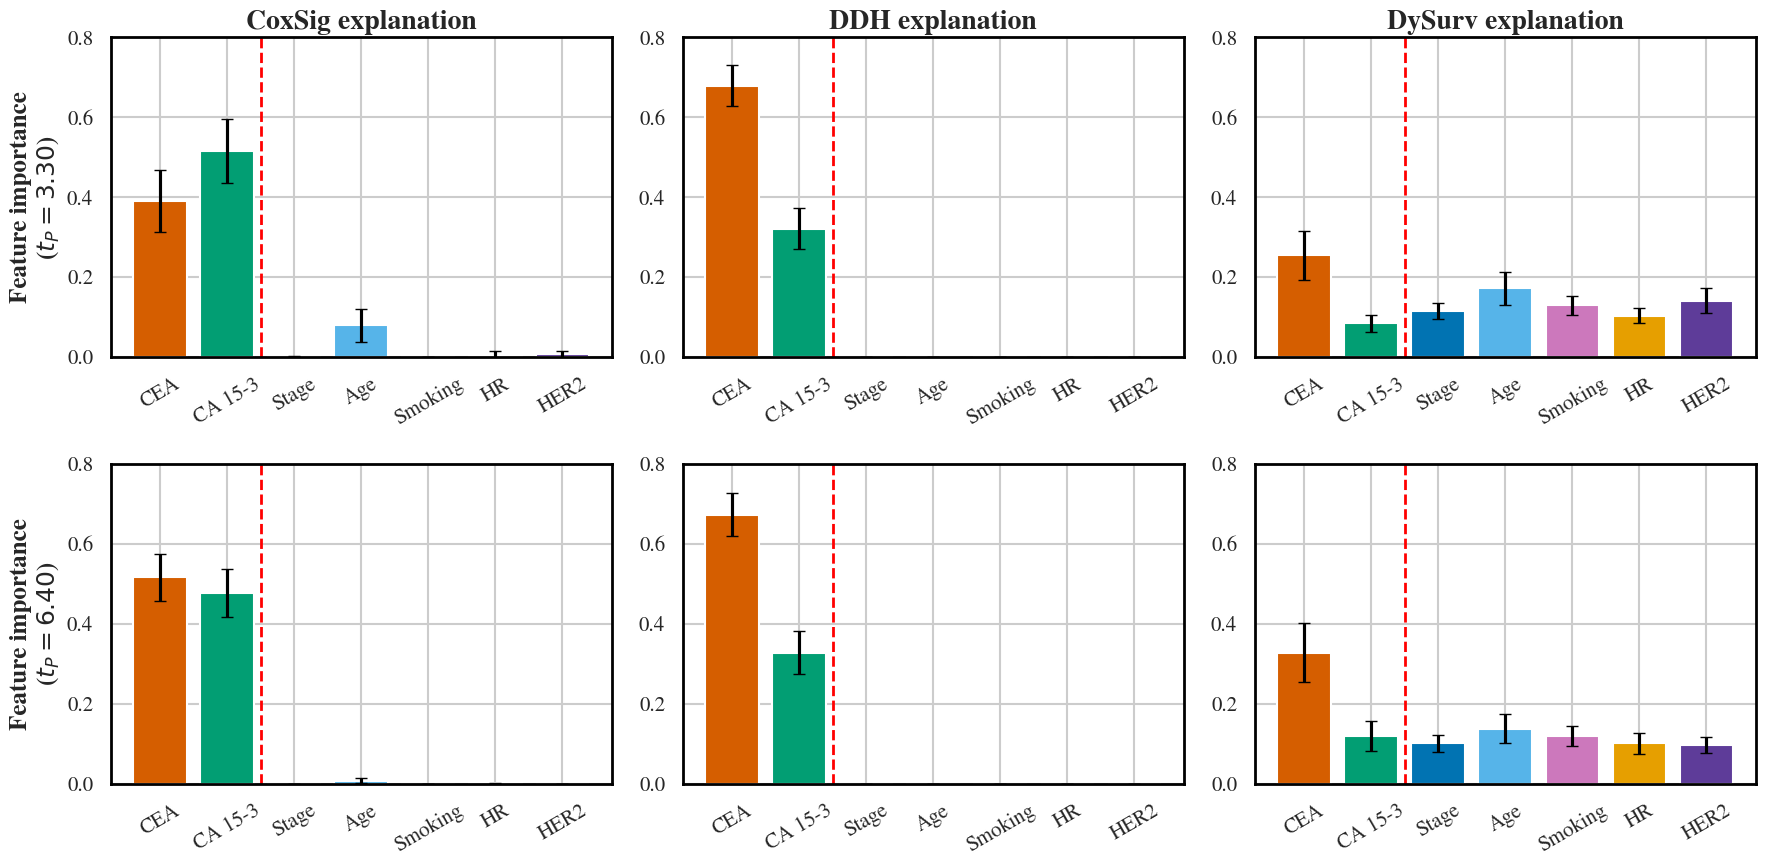

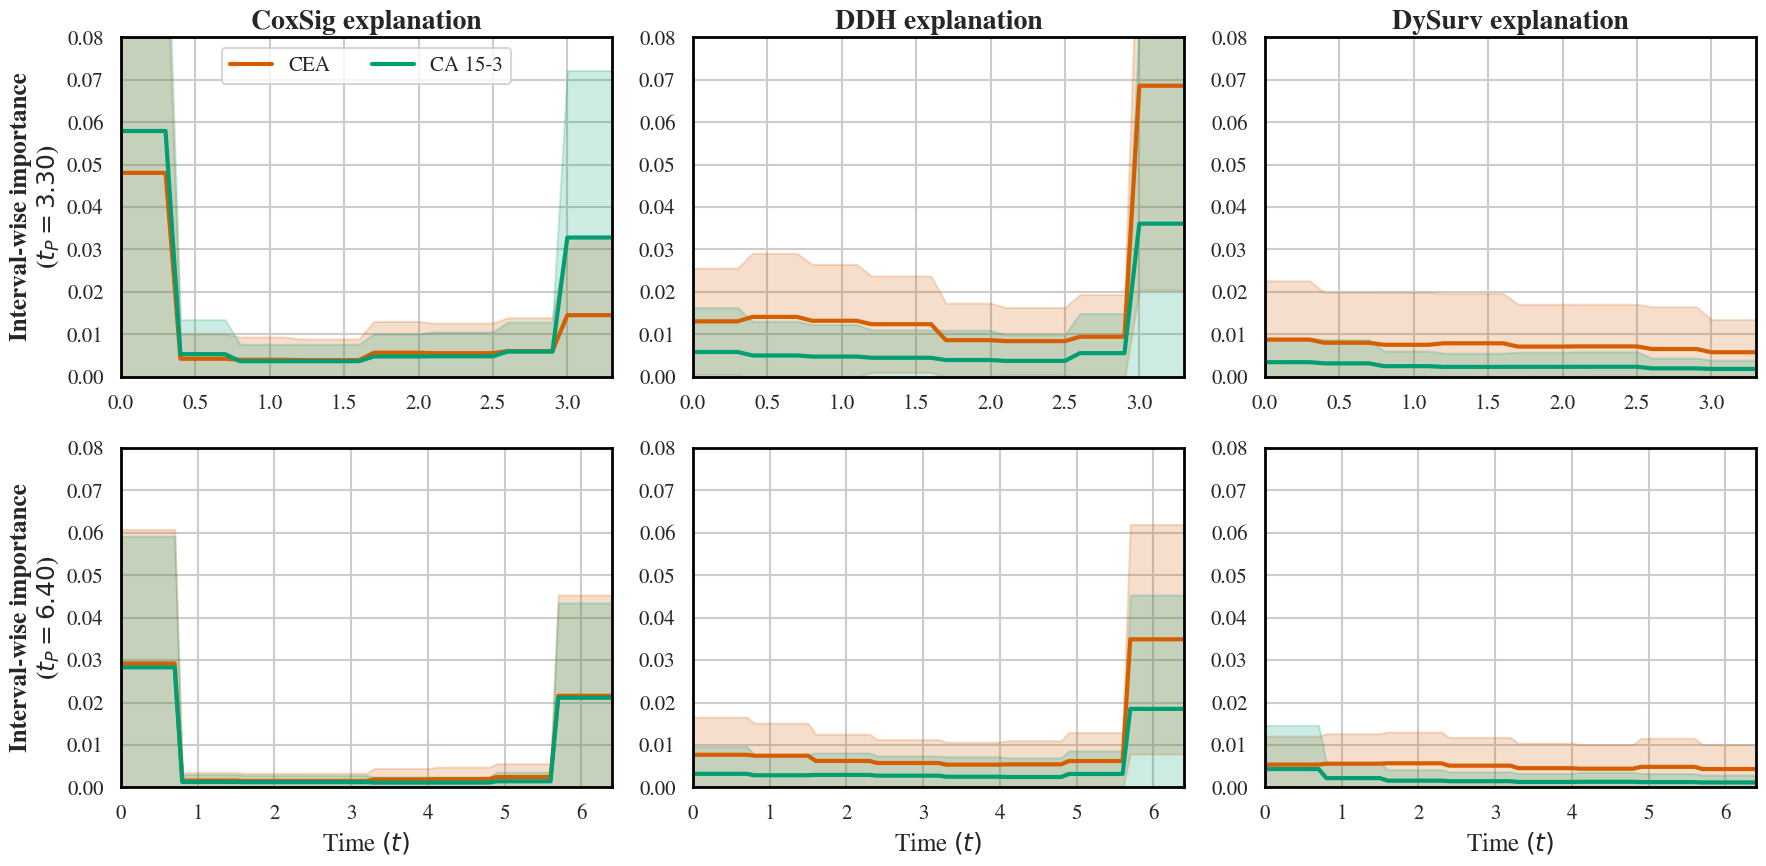

In [10]:
compare_models("med", "global", y_limits=[(0, 0.8)] * len(pred_times))
compare_models("med", "temporal", y_limits=[(0, 0.08)] * len(pred_times))